In [49]:

# If needed, install the required libraries
# Run this line in Google Colab or Jupyter:
# %pip install tensorflow pandas numpy matplotlib scikit-learn seaborn

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)


TensorFlow version: 2.21.0
GPU available: False


In [50]:

# Change this path if your dataset is stored elsewhere
TRAIN_PATH = "/content/train.csv.zip"

# Load the labeled dataset
df = pd.read_csv(TRAIN_PATH)

# Examine the dataset
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist()[:10])

# Check which digit classes are present
print("\nNumber of examples in each class:")
print(df["label"].value_counts().sort_index())


Dataset shape: (60000, 785)

First five rows:


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



Column names:
['label', 'pixel0', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5', 'pixel6', 'pixel7', 'pixel8']

Number of examples in each class:
label
0    6000
1    6000
2    6000
3    6000
4    6000
5    6000
6    6000
7    6000
8    6000
9    6000
Name: count, dtype: int64


In [51]:

# Separate the target labels
y = df["label"].to_numpy(dtype=np.int64)

# Select pixel columns, excluding label and any identifier column
excluded_columns = {"label", "id", "ID", "index"}
pixel_columns = [
    col for col in df.columns
    if col not in excluded_columns
]

# Convert pixel values into a NumPy array
X = df[pixel_columns].to_numpy(dtype=np.float32)

print("Original X shape:", X.shape)
print("Label shape:", y.shape)
print("Unique labels:", np.unique(y))


Original X shape: (60000, 784)
Label shape: (60000,)
Unique labels: [0 1 2 3 4 5 6 7 8 9]


In [52]:

import numpy as np

# Suppose X contains the images after loading the dataset.
# Each image initially contains 784 pixel values.

# Step 1: Convert pixel values to NumPy array
X = np.array(X, dtype=np.float32)

# Step 2: Reshape each image into 28 rows and 28 columns
X_seq = X.reshape(-1, 28, 28)

# Step 3: Display the shape of the sequential data
print("Sequential data shape:", X_seq.shape)

# Step 4: Select the first image
image = X_seq[0]

print("One image shape:", image.shape)

# Step 5: Extract each row as a time-step input
for t in range(28):
    x_t = image[t]
    print(f"Time step {t+1}: shape = {x_t.shape}")


Sequential data shape: (60000, 28, 28)
One image shape: (28, 28)
Time step 1: shape = (28,)
Time step 2: shape = (28,)
Time step 3: shape = (28,)
Time step 4: shape = (28,)
Time step 5: shape = (28,)
Time step 6: shape = (28,)
Time step 7: shape = (28,)
Time step 8: shape = (28,)
Time step 9: shape = (28,)
Time step 10: shape = (28,)
Time step 11: shape = (28,)
Time step 12: shape = (28,)
Time step 13: shape = (28,)
Time step 14: shape = (28,)
Time step 15: shape = (28,)
Time step 16: shape = (28,)
Time step 17: shape = (28,)
Time step 18: shape = (28,)
Time step 19: shape = (28,)
Time step 20: shape = (28,)
Time step 21: shape = (28,)
Time step 22: shape = (28,)
Time step 23: shape = (28,)
Time step 24: shape = (28,)
Time step 25: shape = (28,)
Time step 26: shape = (28,)
Time step 27: shape = (28,)
Time step 28: shape = (28,)


In [53]:
# Split off 15% for the held-out test set
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X_seq,
    y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

# Split the remaining data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.15 / 0.85,
    random_state=42,
    stratify=y_train_val
)

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Test data:", X_test.shape)

Training data: (42000, 28, 28)
Validation data: (9000, 28, 28)
Test data: (9000, 28, 28)


In [54]:

# Normalize pixel values from [0, 255] to [0, 1]
X = X / 255.0

print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())


Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [55]:

# Convert each flattened image into a sequence of 28 rows
X = X.reshape(-1, 28, 28)

print("Sequence data shape:", X.shape)
print("One image shape:", X[0].shape)
print("One time step shape:", X[0, 0].shape)


Sequence data shape: (60000, 28, 28)
One image shape: (28, 28)
One time step shape: (28,)


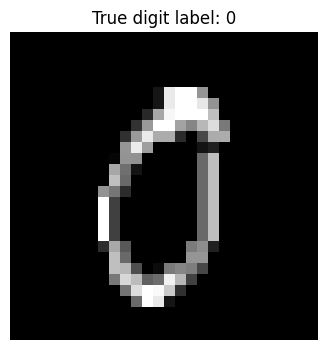

First row of the image:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0.]


In [56]:

index = 0

plt.figure(figsize=(4, 4))
plt.imshow(X[index], cmap="gray")
plt.title(f"True digit label: {y[index]}")
plt.axis("off")
plt.show()

# Print the first row as a sequence of 28 pixel values
print("First row of the image:")
print(X[index, 0])


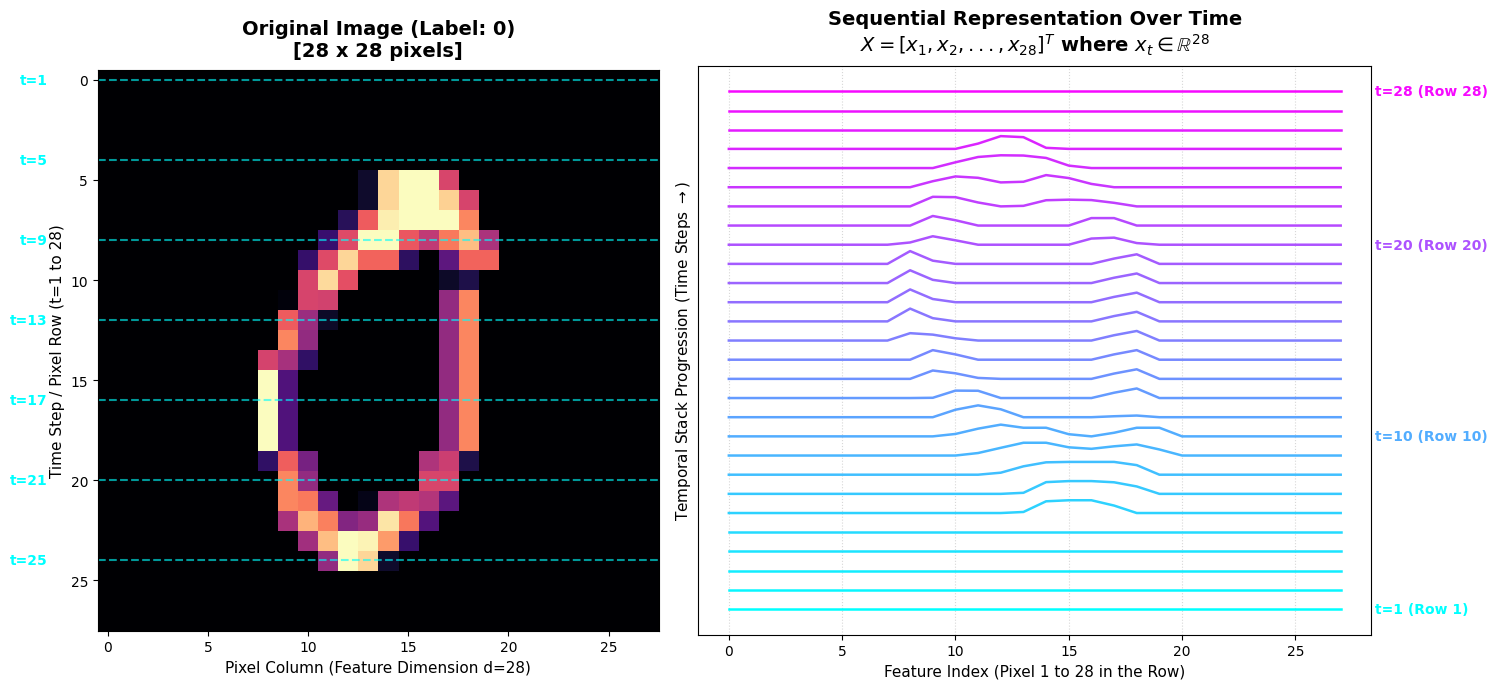

In [57]:
import matplotlib.pyplot as plt
import numpy as np

# Select the first image in the sequence
img_index = 0
single_image = X[img_index]
label = y[img_index]

# Create a beautifully formatted visualization
fig, axes = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={'width_ratios': [1, 1.2]})

# Left Panel: Original image showing row partitions
axes[0].imshow(single_image, cmap='magma')
axes[0].set_title(f"Original Image (Label: {label})\n[28 x 28 pixels]", fontsize=14, fontweight='bold', pad=10)
axes[0].set_xlabel("Pixel Column (Feature Dimension d=28)", fontsize=11)
axes[0].set_ylabel("Time Step / Pixel Row (t=1 to 28)", fontsize=11)

for r in range(0, 28, 4):
    axes[0].axhline(y=r, color='cyan', linestyle='--', alpha=0.6)
    axes[0].text(-3, r, f"t={r+1}", color='cyan', fontsize=10, fontweight='bold', va='center', ha='right')

# Right Panel: Individual row vectors (features) stacked sequentially over time
timesteps = list(range(28))
row_vectors = [single_image[t] for t in timesteps]

for i, t in enumerate(timesteps):
    axes[1].plot(row_vectors[i] + i*1.5, color=plt.cm.cool(i/28), linewidth=1.8)
    if t in [0, 9, 19, 27]:
        axes[1].text(28.5, row_vectors[i][-1] + i*1.5, f"t={t+1} (Row {t+1})", color=plt.cm.cool(t/28), fontweight='bold', va='center')

# Setting titles using raw strings to prevent any LaTeX syntax errors
axes[1].set_title("Sequential Representation Over Time\n" + r"$X = [x_1, x_2, ..., x_{28}]^T$ where $x_t \in \mathbb{R}^{28}$", fontsize=14, fontweight='bold', pad=10)
axes[1].set_xlabel("Feature Index (Pixel 1 to 28 in the Row)", fontsize=11)
axes[1].set_ylabel(r"Temporal Stack Progression (Time Steps $\rightarrow$)", fontsize=11)
axes[1].set_yticks([])
axes[1].grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

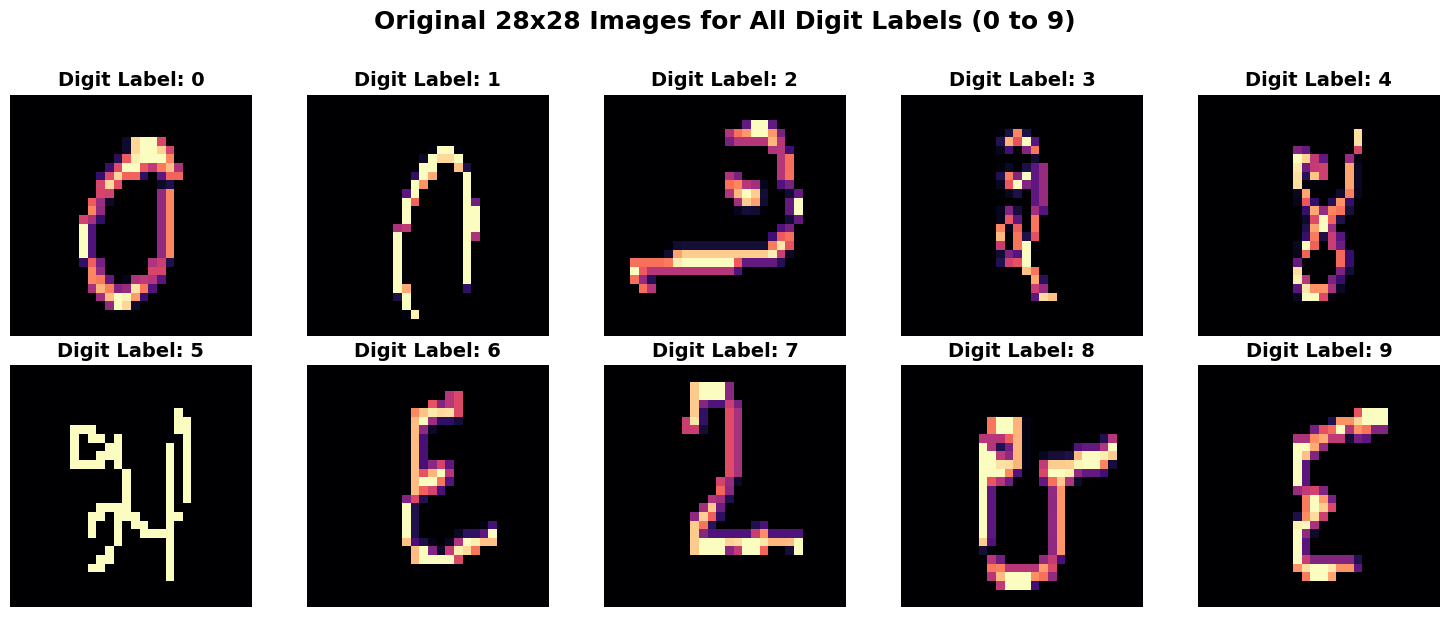

In [58]:
import matplotlib.pyplot as plt
import numpy as np

# Find the first index for each label (0 to 9) in the dataset
unique_labels = np.arange(10)
sample_indices = [np.where(y == label)[0][0] for label in unique_labels]

# Create a neat 2x5 grid of subplots to display the original images
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()

for idx, label in enumerate(unique_labels):
    img_idx = sample_indices[idx]
    img = X[img_idx]

    # Display the original 28x28 image
    axes[idx].imshow(img, cmap='magma')
    axes[idx].set_title(f"Digit Label: {label}", fontsize=14, fontweight='bold')
    axes[idx].axis('off')

fig.suptitle("Original 28x28 Images for All Digit Labels (0 to 9)", fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

<>:30: SyntaxWarning: invalid escape sequence '\i'
<>:30: SyntaxWarning: invalid escape sequence '\i'
/tmp/ipykernel_2632/663612663.py:30: SyntaxWarning: invalid escape sequence '\i'
  fig.suptitle("Sequential Temporal Representations $X \in \mathbb{R}^{28 \times 28}$ for All Digit Labels (0 to 9)", fontsize=18, fontweight='bold', y=0.98)


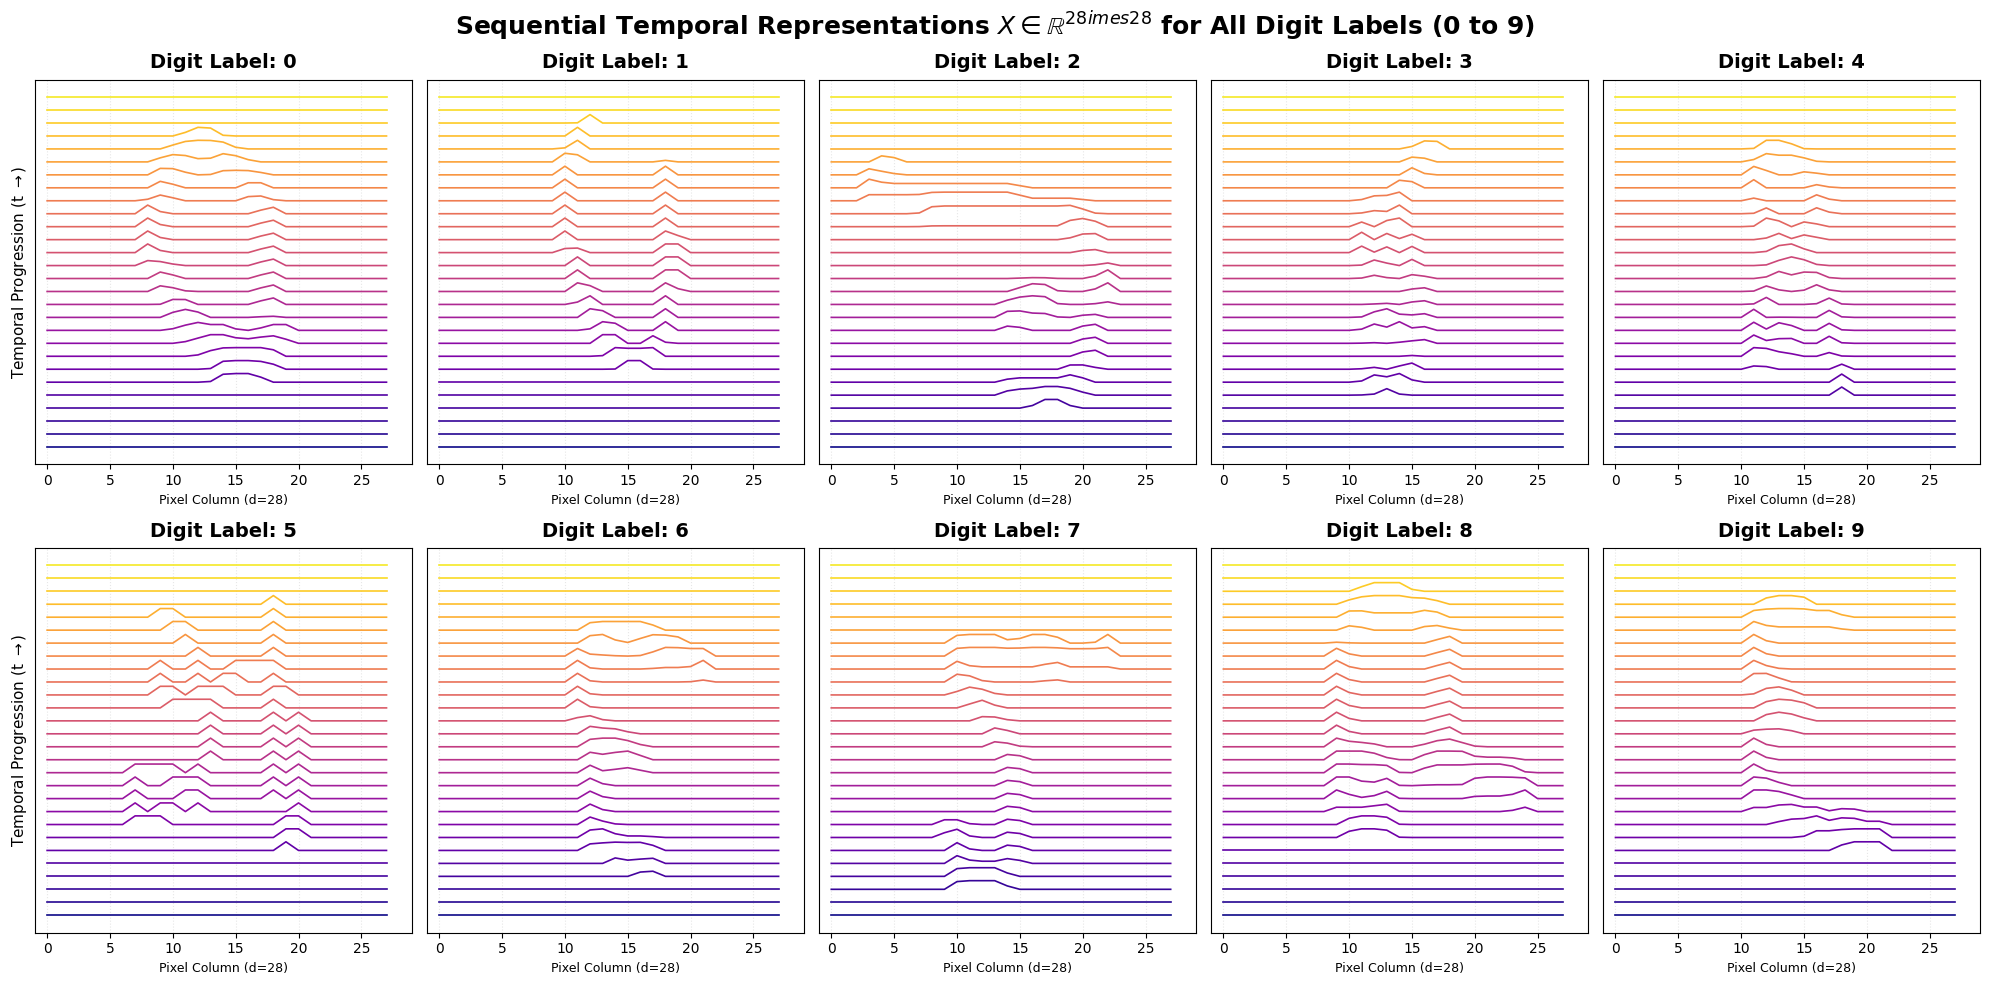

In [59]:
import matplotlib.pyplot as plt
import numpy as np

# Find the first index for each label (0 to 9) in the dataset
unique_labels = np.arange(10)
sample_indices = [np.where(y == label)[0][0] for label in unique_labels]

# Create a beautiful 2x5 grid of subplots for all 10 labels
fig, axes = plt.subplots(2, 5, figsize=(20, 10))
axes = axes.flatten()

for idx, label in enumerate(unique_labels):
    img_idx = sample_indices[idx]
    img = X[img_idx]

    # Generate sequential representation (the 28 row vectors stacked)
    timesteps = np.arange(28)
    for t in timesteps:
        # Plot each row vector shifted upward by its timestep index to simulate the temporal progression
        axes[idx].plot(img[t] + t * 1.5, color=plt.cm.plasma(t / 28.0), linewidth=1.2)

    axes[idx].set_title(f"Digit Label: {label}", fontsize=14, fontweight='bold', pad=8)
    axes[idx].set_xlabel("Pixel Column (d=28)", fontsize=9)
    if idx % 5 == 0:
        axes[idx].set_ylabel(r"Temporal Progression (t $\rightarrow$)", fontsize=11)
    axes[idx].set_yticks([])
    axes[idx].set_xlim(-1, 29)
    axes[idx].grid(True, linestyle=':', alpha=0.3)

fig.suptitle("Sequential Temporal Representations $X \in \mathbb{R}^{28 \times 28}$ for All Digit Labels (0 to 9)", fontsize=18, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

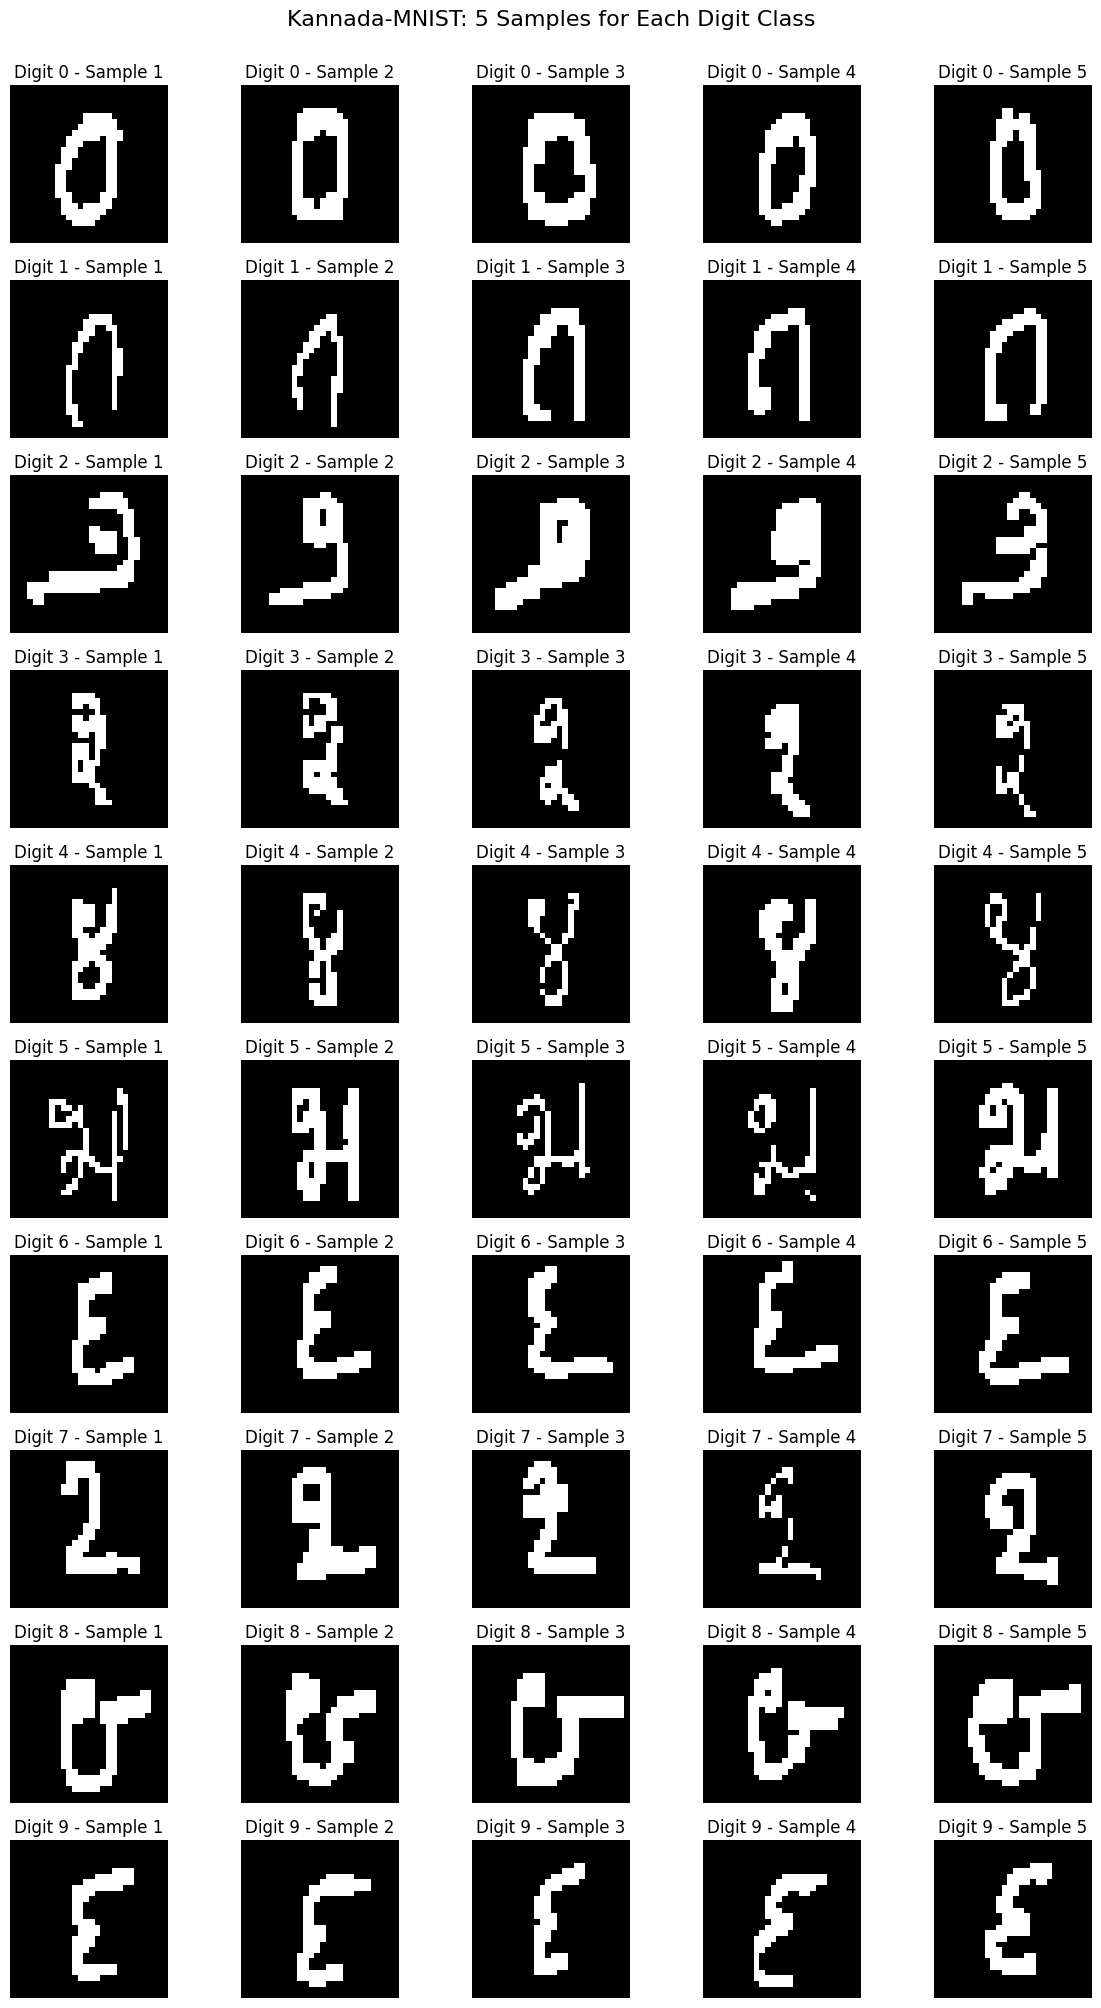

In [60]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# X_seq: images with shape (number_of_images, 28, 28)
# y: corresponding labels (digits 0 to 9)

# Number of samples per digit class
samples_per_class = 5

# Create a figure with 10 rows and 5 columns
fig, axes = plt.subplots(
    nrows=10,
    ncols=samples_per_class,
    figsize=(12, 20)
)

for digit in range(10):

    # Find the indices of images belonging to this digit
    digit_indices = np.where(y == digit)[0]

    # Select the first 5 samples of this class
    selected_indices = digit_indices[:samples_per_class]

    for j, idx in enumerate(selected_indices):

        ax = axes[digit, j]

        # Display the image as a grayscale heatmap
        ax.imshow(X_seq[idx], cmap="gray", vmin=0, vmax=1)

        ax.set_title(f"Digit {digit} - Sample {j + 1}")
        ax.axis("off")

# Add an overall title
fig.suptitle(
    "Kannada-MNIST: 5 Samples for Each Digit Class",
    fontsize=16,
    y=1.002
)

plt.tight_layout()
plt.show()


In [61]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input, SimpleRNN, LSTM, GRU, Dense, Dropout
)
from tensorflow.keras.optimizers import Adam

def build_model(model_type):
    model = Sequential([
        Input(shape=(28, 28))
    ])

    if model_type == "RNN":
        model.add(SimpleRNN(128))

    elif model_type == "LSTM":
        model.add(LSTM(128))

    elif model_type == "GRU":
        model.add(GRU(128))

    model.add(Dropout(0.3))
    model.add(Dense(64, activation="relu"))
    model.add(Dropout(0.2))
    model.add(Dense(10, activation="softmax"))

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [62]:
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau
)

MODEL_TYPES = ["RNN", "LSTM", "GRU"]

results = []
trained_models = {}
histories = {}

for model_type in MODEL_TYPES:
    print(f"\nTraining {model_type} model...")

    tf.keras.backend.clear_session()
    model = build_model(model_type)

    callbacks = [
        EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True,
            verbose=1
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-6,
            verbose=1
        )
    ]

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=40,
        batch_size=128,
        callbacks=callbacks,
        verbose=1
    )

    val_loss, val_accuracy = model.evaluate(
        X_val, y_val, verbose=0
    )

    results.append({
        "Model": model_type,
        "Validation Accuracy": val_accuracy,
        "Validation Loss": val_loss,
        "Epochs Trained": len(history.history["loss"])
    })

    trained_models[model_type] = model
    histories[model_type] = history.history

    print(f"{model_type} validation accuracy: "
          f"{val_accuracy:.4f}")


Training RNN model...
Epoch 1/40
329/329 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - accuracy: 0.5008 - loss: 1.3630 - val_accuracy: 0.5779 - val_loss: 1.1449 - learning_rate: 0.0010
Epoch 2/40
329/329 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.5660 - loss: 1.1655 - val_accuracy: 0.5937 - val_loss: 1.0965 - learning_rate: 0.0010
Epoch 3/40
329/329 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.5805 - loss: 1.1248 - val_accuracy: 0.6051 - val_loss: 1.0670 - learning_rate: 0.0010
Epoch 4/40
329/329 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.5928 - loss: 1.0909 - val_accuracy: 0.6150 - val_loss: 1.0486 - learning_rate: 0.0010
Epoch 5/40
329/329 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.6025 - loss: 1.0694 - val_accuracy: 0.6159 - val_loss: 1.0348 - learning_rate: 0.0010
Epoch 6/40
329/329 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.6091 - loss: 1.0479 - val_accuracy: 0.6213 - val_loss: 1.0201 - learning_rate: 0.0010
Epoch 7/40
329/329 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - acc

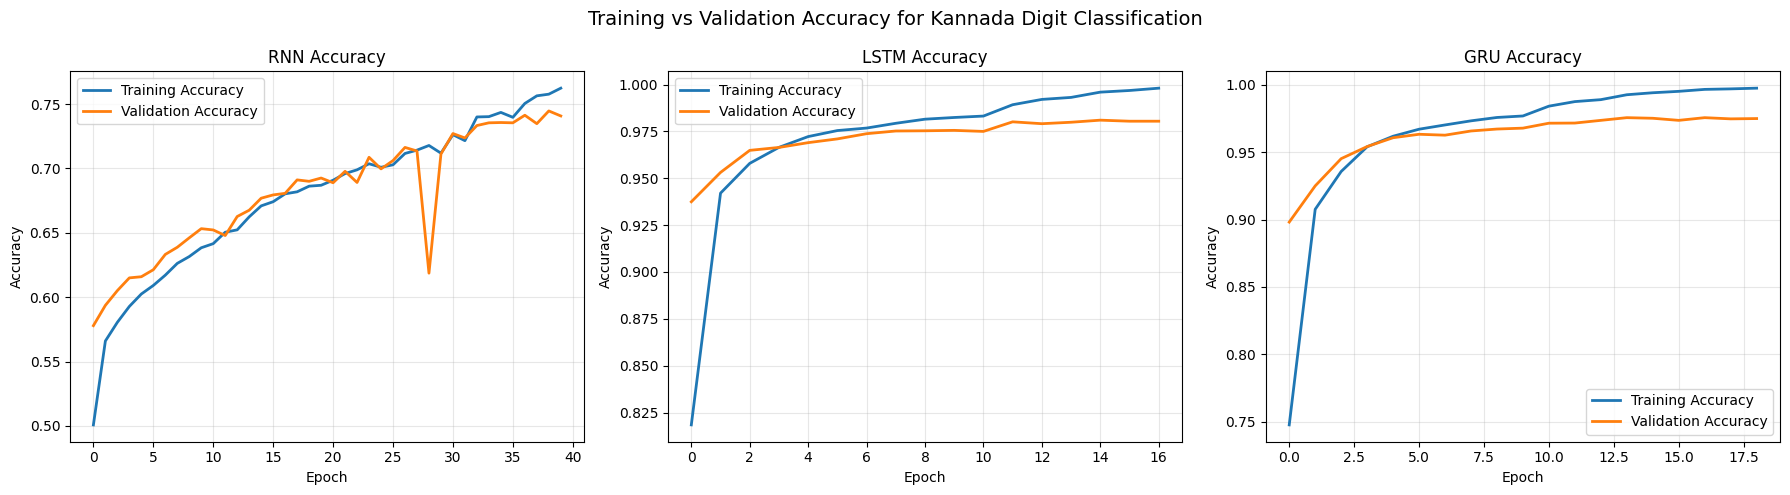

In [64]:
import matplotlib.pyplot as plt

models = ["RNN", "LSTM", "GRU"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, model_name in enumerate(models):
    history = histories[model_name]

    axes[i].plot(
        history["accuracy"],
        label="Training Accuracy",
        linewidth=2
    )

    axes[i].plot(
        history["val_accuracy"],
        label="Validation Accuracy",
        linewidth=2
    )

    axes[i].set_title(f"{model_name} Accuracy")
    axes[i].set_xlabel("Epoch")
    axes[i].set_ylabel("Accuracy")
    axes[i].legend()
    axes[i].grid(True, alpha=0.3)

plt.suptitle(
    "Training vs Validation Accuracy for Kannada Digit Classification",
    fontsize=14
)

plt.tight_layout()
plt.savefig(
    "training_validation_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

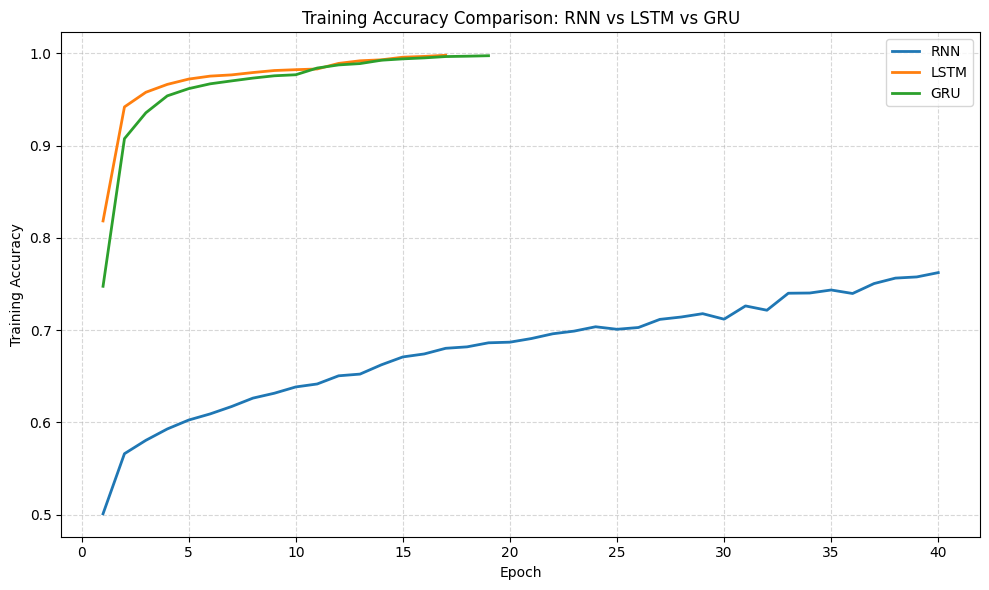

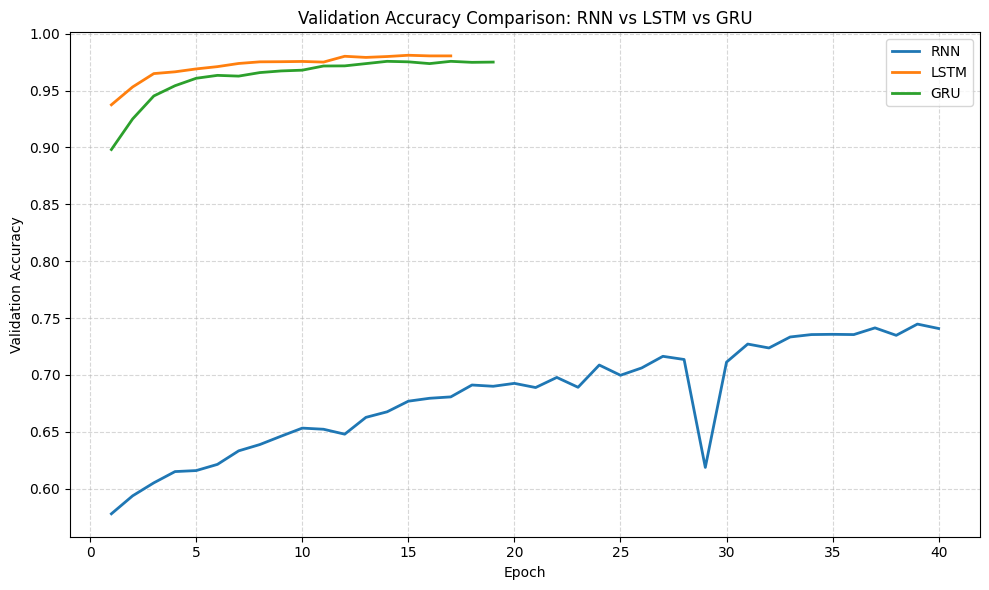

In [65]:
import matplotlib.pyplot as plt

models = ["RNN", "LSTM", "GRU"]

# ==========================================
# Graph 1: Training Accuracy of All 3 Models
# ==========================================
plt.figure(figsize=(10, 6))

for model_name in models:
    history = histories[model_name]

    plt.plot(
        range(1, len(history["accuracy"]) + 1),
        history["accuracy"],
        label=model_name,
        linewidth=2
    )

plt.title("Training Accuracy Comparison: RNN vs LSTM vs GRU")
plt.xlabel("Epoch")
plt.ylabel("Training Accuracy")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig("training_accuracy_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()


# ==========================================
# Graph 2: Validation Accuracy of All 3 Models
# ==========================================
plt.figure(figsize=(10, 6))

for model_name in models:
    history = histories[model_name]

    plt.plot(
        range(1, len(history["val_accuracy"]) + 1),
        history["val_accuracy"],
        label=model_name,
        linewidth=2
    )

plt.title("Validation Accuracy Comparison: RNN vs LSTM vs GRU")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig("validation_accuracy_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()

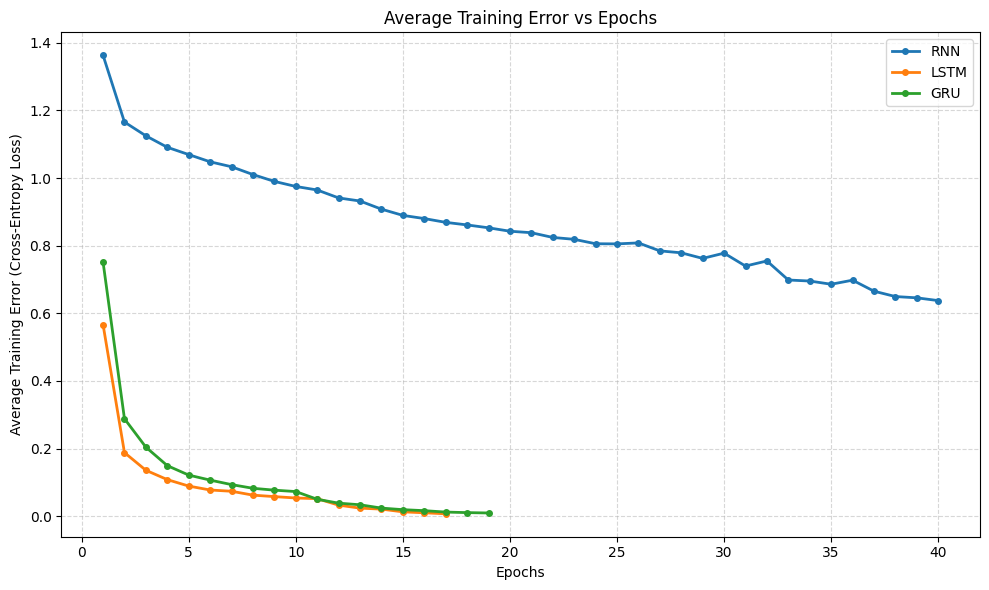

In [66]:
import matplotlib.pyplot as plt

models = ["RNN", "LSTM", "GRU"]

plt.figure(figsize=(10, 6))

for model_name in models:
    history = histories[model_name]

    epochs = range(1, len(history["loss"]) + 1)
    training_error = history["loss"]

    plt.plot(
        epochs,
        training_error,
        label=model_name,
        linewidth=2,
        marker="o",
        markersize=4
    )

plt.title("Average Training Error vs Epochs")
plt.xlabel("Epochs")
plt.ylabel("Average Training Error (Cross-Entropy Loss)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig(
    "average_training_error_vs_epochs.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [67]:
import pandas as pd
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, SimpleRNN, LSTM, GRU, Dense

results = []

# Only 2 hyperparameter sets to reduce execution time
configs = [
    {"units": 64, "lr": 0.001, "batch": 128},
    {"units": 128, "lr": 0.001, "batch": 128}
]

layers = {"RNN": SimpleRNN, "LSTM": LSTM, "GRU": GRU}

for name, layer in layers.items():
    for hp in configs:
        model = Sequential([
            Input(shape=(28, 28)),
            layer(hp["units"]),
            Dense(10, activation="softmax")
        ])

        model.compile(
            optimizer=tf.keras.optimizers.Adam(hp["lr"]),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"]
        )

        model.fit(
            X_train, y_train,
            epochs=5,                 # Fewer epochs = faster
            batch_size=hp["batch"],
            verbose=0
        )

        # Calculate actual accuracies
        _, train_acc = model.evaluate(X_train, y_train, verbose=0)
        _, test_acc = model.evaluate(X_test, y_test, verbose=0)

        results.append({
            "Model": name,
            "Units": hp["units"],
            "Learning Rate": hp["lr"],
            "Batch Size": hp["batch"],
            "Training Accuracy (%)": round(train_acc * 100, 2),
            "Test Accuracy (%)": round(test_acc * 100, 2)
        })

        # Print results immediately
        print(
            f"{name} | Units={hp['units']} | "
            f"Train Acc={train_acc*100:.2f}% | "
            f"Test Acc={test_acc*100:.2f}%"
        )

# Display complete summary table
df = pd.DataFrame(results)
print("\nFINAL ACCURACY SUMMARY")
print(df.to_string(index=False))

df.to_csv("accuracy_summary.csv", index=False)

RNN | Units=64 | Train Acc=60.71% | Test Acc=59.93%
RNN | Units=128 | Train Acc=64.59% | Test Acc=63.81%
LSTM | Units=64 | Train Acc=96.81% | Test Acc=95.52%
LSTM | Units=128 | Train Acc=98.54% | Test Acc=97.19%
GRU | Units=64 | Train Acc=93.25% | Test Acc=91.94%
GRU | Units=128 | Train Acc=97.16% | Test Acc=95.40%

FINAL ACCURACY SUMMARY
Model  Units  Learning Rate  Batch Size  Training Accuracy (%)  Test Accuracy (%)
  RNN     64          0.001         128                  60.71              59.93
  RNN    128          0.001         128                  64.59              63.81
 LSTM     64          0.001         128                  96.81              95.52
 LSTM    128          0.001         128                  98.54              97.19
  GRU     64          0.001         128                  93.25              91.94
  GRU    128          0.001         128                  97.16              95.40


In [68]:
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, SimpleRNN, LSTM, GRU, Dense

# Best hyperparameters for each model (change if needed)
best_params = {
    "RNN":  {"layer": SimpleRNN, "units": 64,  "lr": 0.001, "batch": 128},
    "LSTM": {"layer": LSTM,      "units": 64,  "lr": 0.001, "batch": 128},
    "GRU":  {"layer": GRU,       "units": 64,  "lr": 0.001, "batch": 128}
}

results = {}

for name, hp in best_params.items():
    print(f"\nTraining {name}...")

    model = Sequential([
        Input(shape=(28, 28)),
        hp["layer"](hp["units"]),
        Dense(10, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=hp["lr"]),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    model.fit(
        X_train, y_train,
        epochs=5,
        batch_size=hp["batch"],
        verbose=1
    )

    # Final training and test accuracy
    _, train_acc = model.evaluate(X_train, y_train, verbose=0)
    _, test_acc = model.evaluate(X_test, y_test, verbose=0)

    # Predictions and confusion matrix
    y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
    cm = confusion_matrix(y_test, y_pred, labels=np.arange(10))

    results[name] = {
        "Training Accuracy (%)": round(train_acc * 100, 2),
        "Test Accuracy (%)": round(test_acc * 100, 2)
    }

    print(f"\n{name} Results")
    print(f"Final Training Accuracy: {train_acc * 100:.2f}%")
    print(f"Test Accuracy:           {test_acc * 100:.2f}%")

    print("\nConfusion Matrix (rows = actual, columns = predicted):")
    print(pd.DataFrame(
        cm,
        index=[f"Actual {i}" for i in range(10)],
        columns=[f"Predicted {i}" for i in range(10)]
    ))

    print("\nClassification Report:")
    print(classification_report(
        y_test, y_pred,
        labels=np.arange(10),
        zero_division=0
    ))

# Summary table
summary = pd.DataFrame(results).T
print("\nFINAL PERFORMANCE SUMMARY")
print(summary)

summary.to_csv("performance_summary.csv")
print("\nSaved summary to performance_summary.csv")


Training RNN...
Epoch 1/5
329/329 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.4897 - loss: 1.4061
Epoch 2/5
329/329 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.5706 - loss: 1.1479
Epoch 3/5
329/329 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5856 - loss: 1.1071
Epoch 4/5
329/329 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5954 - loss: 1.0860
Epoch 5/5
329/329 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.5996 - loss: 1.0674

RNN Results
Final Training Accuracy: 60.40%
Test Accuracy:           59.86%

Confusion Matrix (rows = actual, columns = predicted):
          Predicted 0  Predicted 1  Predicted 2  Predicted 3  Predicted 4  \
Actual 0          350           18            2           19          292   
Actual 1            0          701            2           16           18   
Actual 2            1            1          780           15            4   
Actual 3           15           20            4          591           39   
Actual 4           81           16     


Training RNN...
Epoch 1/8
329/329 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.4927 - loss: 1.4131 - val_accuracy: 0.5566 - val_loss: 1.2032
Epoch 2/8
329/329 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.5700 - loss: 1.1609 - val_accuracy: 0.5777 - val_loss: 1.1461
Epoch 3/8
329/329 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.5856 - loss: 1.1138 - val_accuracy: 0.5884 - val_loss: 1.1177
Epoch 4/8
329/329 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.5946 - loss: 1.0873 - val_accuracy: 0.5944 - val_loss: 1.0974
Epoch 5/8
329/329 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.5989 - loss: 1.0684 - val_accuracy: 0.5953 - val_loss: 1.0862
Epoch 6/8
329/329 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.6037 - loss: 1.0543 - val_accuracy: 0.5989 - val_loss: 1.0811
Epoch 7/8
329/329 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6060 - loss: 1.0440 - val_accuracy: 0.6031 - val_loss: 1.0754
Epoch 8/8
329/329 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.6107 - loss: 1.0355 - val_ac

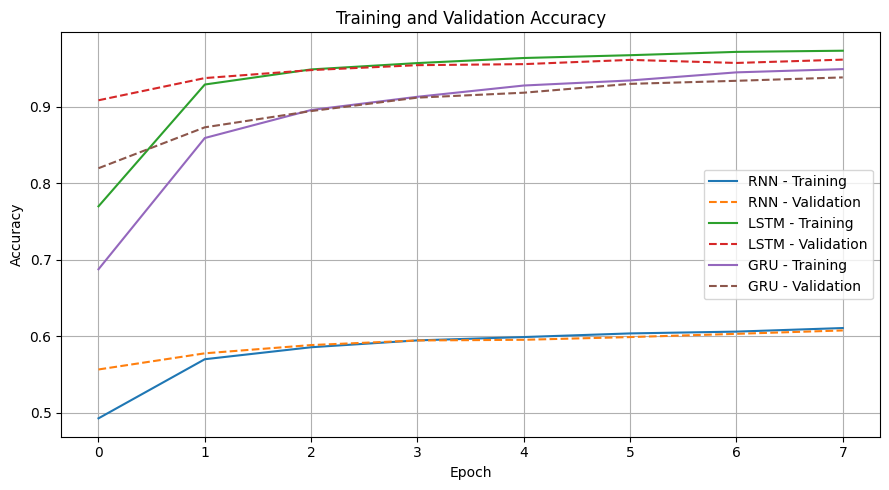

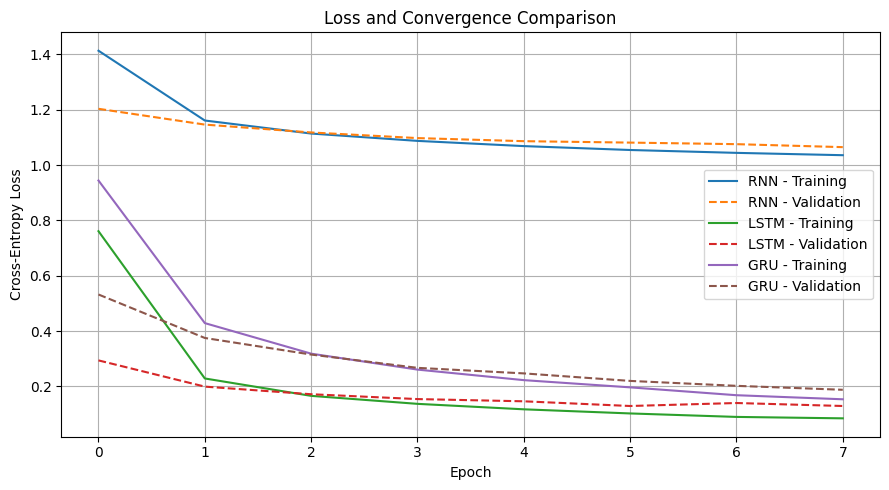

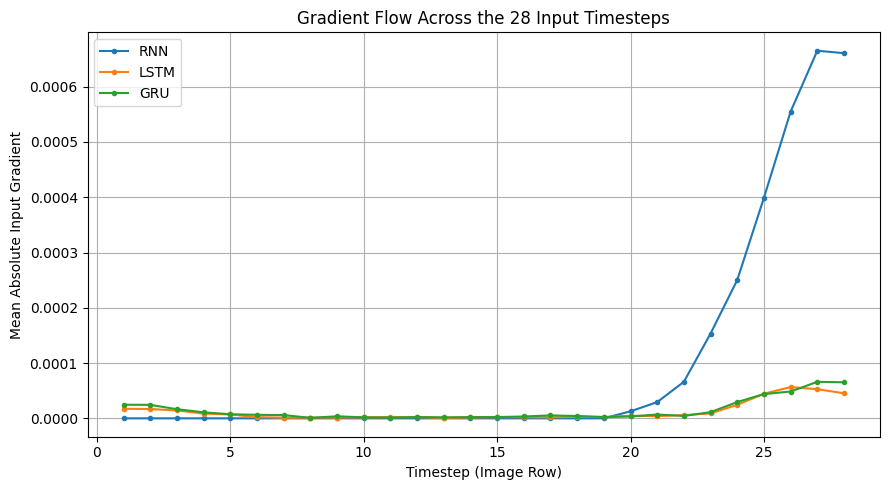


FINAL COMPARATIVE PERFORMANCE
      Training Accuracy (%)  Validation Accuracy (%)  Training Loss  Validation Loss  Best Validation Epoch  Best Validation Accuracy (%)  Mean Input Gradient  Minimum Input Gradient
RNN                   61.39                    60.76         1.0194           1.0647                    8.0                         60.76             0.000100            1.769073e-23
LSTM                  97.72                    96.14         0.0728           0.1292                    8.0                         96.14             0.000012            7.059806e-07
GRU                   95.56                    93.82         0.1360           0.1878                    8.0                         93.82             0.000015            9.252161e-07

Saved: comparative_analysis.csv
Saved: accuracy_comparison.png
Saved: loss_convergence.png
Saved: gradient_flow.png


In [69]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, SimpleRNN, LSTM, GRU, Dense

# Set the same hyperparameters for a fair comparison
EPOCHS = 8
UNITS = 64
BATCH_SIZE = 128
LEARNING_RATE = 0.001

layers = {
    "RNN": SimpleRNN,
    "LSTM": LSTM,
    "GRU": GRU
}

models = {}
histories = {}
results = {}
gradient_results = {}

# 1. Train all three models
for name, layer in layers.items():
    print(f"\nTraining {name}...")

    model = Sequential([
        Input(shape=(28, 28)),
        layer(UNITS),
        Dense(10, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        verbose=1
    )

    models[name] = model
    histories[name] = history.history

    train_loss, train_acc = model.evaluate(
        X_train, y_train, verbose=0
    )
    val_loss, val_acc = model.evaluate(
        X_val, y_val, verbose=0
    )

    best_epoch = np.argmax(history.history["val_accuracy"]) + 1

    results[name] = {
        "Training Accuracy (%)": round(train_acc * 100, 2),
        "Validation Accuracy (%)": round(val_acc * 100, 2),
        "Training Loss": round(train_loss, 4),
        "Validation Loss": round(val_loss, 4),
        "Best Validation Epoch": int(best_epoch),
        "Best Validation Accuracy (%)": round(
            max(history.history["val_accuracy"]) * 100, 2
        )
    }

    print(
        f"{name}: Training Accuracy = {train_acc * 100:.2f}%, "
        f"Validation Accuracy = {val_acc * 100:.2f}%"
    )

# 2. Plot training and validation accuracy
plt.figure(figsize=(9, 5))

for name, history in histories.items():
    plt.plot(history["accuracy"], label=f"{name} - Training")
    plt.plot(history["val_accuracy"], linestyle="--",
             label=f"{name} - Validation")

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("accuracy_comparison.png", dpi=300)
plt.show()

# 3. Plot training and validation loss (convergence)
plt.figure(figsize=(9, 5))

for name, history in histories.items():
    plt.plot(history["loss"], label=f"{name} - Training")
    plt.plot(history["val_loss"], linestyle="--",
             label=f"{name} - Validation")

plt.title("Loss and Convergence Comparison")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("loss_convergence.png", dpi=300)
plt.show()

# 4. Measure gradient flow through the input sequence
# Use the same validation batch for each model.
x_batch = tf.convert_to_tensor(X_val[:128], dtype=tf.float32)
y_batch = tf.convert_to_tensor(y_val[:128], dtype=tf.int32)

for name, model in models.items():
    with tf.GradientTape() as tape:
        tape.watch(x_batch)
        predictions = model(x_batch, training=False)
        loss = tf.keras.losses.sparse_categorical_crossentropy(
            y_batch, predictions
        )
        loss = tf.reduce_mean(loss)

    # Gradient of loss with respect to each input pixel
    gradients = tape.gradient(loss, x_batch)

    # Average absolute gradient over samples and pixel columns.
    # Result contains one value per image row / timestep.
    timestep_gradients = tf.reduce_mean(
        tf.abs(gradients), axis=[0, 2]
    ).numpy()

    gradient_results[name] = timestep_gradients

# 5. Plot gradient magnitude by timestep
plt.figure(figsize=(9, 5))

for name, values in gradient_results.items():
    plt.plot(
        np.arange(1, 29), values,
        marker="o", markersize=3, label=name
    )

plt.title("Gradient Flow Across the 28 Input Timesteps")
plt.xlabel("Timestep (Image Row)")
plt.ylabel("Mean Absolute Input Gradient")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("gradient_flow.png", dpi=300)
plt.show()

# 6. Compare average gradient magnitudes
for name, values in gradient_results.items():
    results[name]["Mean Input Gradient"] = float(
        np.mean(values)
    )
    results[name]["Minimum Input Gradient"] = float(
        np.min(values)
    )

summary = pd.DataFrame(results).T

print("\nFINAL COMPARATIVE PERFORMANCE")
print(summary.to_string())

summary.to_csv("comparative_analysis.csv")
print("\nSaved: comparative_analysis.csv")
print("Saved: accuracy_comparison.png")
print("Saved: loss_convergence.png")
print("Saved: gradient_flow.png")

 EVALUATION REPORT: RNN MODEL 
Classification Report for RNN:
              precision    recall  f1-score   support

           0     0.4872    0.4244    0.4537       900
           1     0.6896    0.7922    0.7373       900
           2     0.8913    0.8656    0.8782       900
           3     0.6073    0.6444    0.6253       900
           4     0.4758    0.7089    0.5694       900
           5     0.5943    0.5533    0.5731       900
           6     0.6774    0.7467    0.7104       900
           7     0.5144    0.4778    0.4954       900
           8     0.4743    0.2667    0.3414       900
           9     0.5917    0.5522    0.5713       900

    accuracy                         0.6032      9000
   macro avg     0.6003    0.6032    0.5955      9000
weighted avg     0.6003    0.6032    0.5955      9000



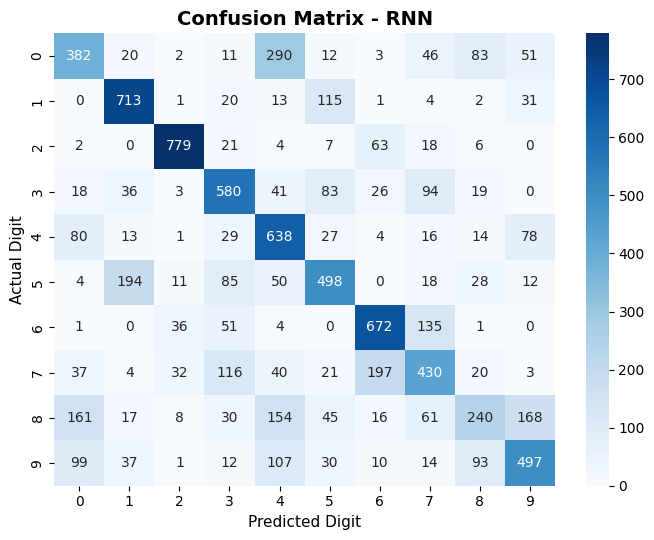



 EVALUATION REPORT: LSTM MODEL 
Classification Report for LSTM:
              precision    recall  f1-score   support

           0     0.9677    0.9333    0.9502       900
           1     0.9788    0.9767    0.9778       900
           2     0.9857    0.9933    0.9895       900
           3     0.9448    0.9500    0.9474       900
           4     0.9469    0.9711    0.9589       900
           5     0.9516    0.9611    0.9563       900
           6     0.9382    0.9622    0.9501       900
           7     0.9373    0.9300    0.9336       900
           8     0.9728    0.9522    0.9624       900
           9     0.9675    0.9600    0.9637       900

    accuracy                         0.9590      9000
   macro avg     0.9591    0.9590    0.9590      9000
weighted avg     0.9591    0.9590    0.9590      9000



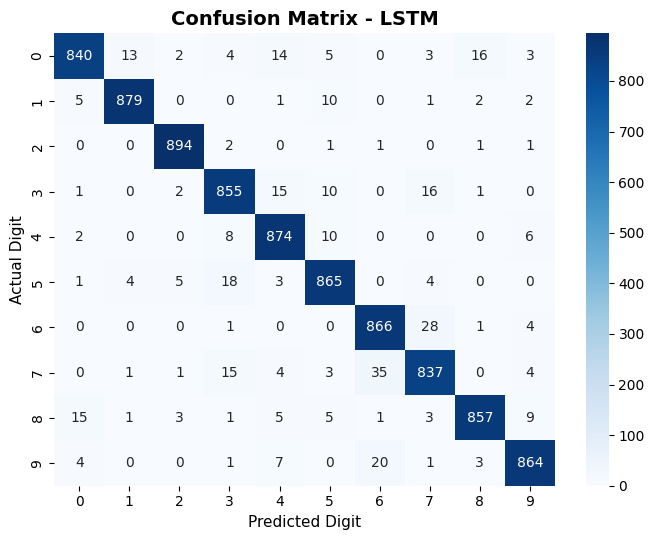



 EVALUATION REPORT: GRU MODEL 
Classification Report for GRU:
              precision    recall  f1-score   support

           0     0.9412    0.9256    0.9333       900
           1     0.9211    0.9600    0.9402       900
           2     0.9846    0.9922    0.9884       900
           3     0.9293    0.9056    0.9173       900
           4     0.9210    0.9200    0.9205       900
           5     0.9386    0.9167    0.9275       900
           6     0.8937    0.9711    0.9308       900
           7     0.9364    0.8667    0.9002       900
           8     0.9606    0.9489    0.9547       900
           9     0.9508    0.9667    0.9587       900

    accuracy                         0.9373      9000
   macro avg     0.9377    0.9373    0.9371      9000
weighted avg     0.9377    0.9373    0.9371      9000



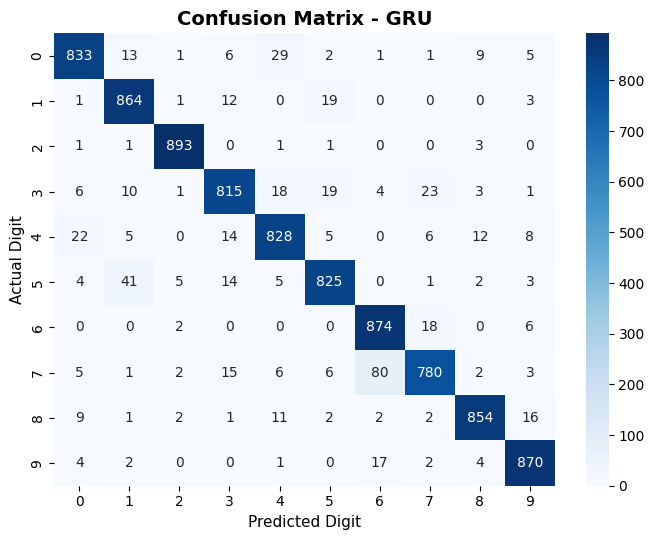

In [70]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# We will use the 'models' dictionary which contains the trained sequential models
for name, model in models.items():
    print("="*60)
    print(f" EVALUATION REPORT: {name} MODEL ")
    print("="*60)

    # Predict probabilities and get class indices
    y_pred_probs = model.predict(X_test, verbose=0)
    y_pred = np.argmax(y_pred_probs, axis=1)

    # Generate classification report
    print(f"Classification Report for {name}:")
    print(classification_report(y_test, y_pred, digits=4))

    # Compute confusion matrix
    cm = confusion_matrix(y_test, y_pred, labels=range(10))

    # Plot confusion matrix
    plt.figure(figsize=(7, 5.5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=range(10),
        yticklabels=range(10)
    )
    plt.title(f"Confusion Matrix - {name}", fontsize=14, fontweight='bold')
    plt.xlabel("Predicted Digit", fontsize=11)
    plt.ylabel("Actual Digit", fontsize=11)
    plt.tight_layout()
    plt.show()
    print("\n")

In [71]:
import pandas as pd

# We can find the best model directly from our 'results' dictionary
best_model_name = max(
    results,
    key=lambda name: results[name]["Validation Accuracy (%)"]
)

print(f"The best model based on Validation Accuracy is: {best_model_name}")
print("\nDetails:")
for metric, val in results[best_model_name].items():
    print(f" - {metric}: {val}")


The best model based on Validation Accuracy is: LSTM

Details:
 - Training Accuracy (%): 97.72
 - Validation Accuracy (%): 96.14
 - Training Loss: 0.0728
 - Validation Loss: 0.1292
 - Best Validation Epoch: 8
 - Best Validation Accuracy (%): 96.14
 - Mean Input Gradient: 1.2037033229717053e-05
 - Minimum Input Gradient: 7.059805966491695e-07


Selected model: LSTM
Test accuracy: 0.2734
Test accuracy (%): 27.34%

Classification Report:
              precision    recall  f1-score   support

           0     0.0337    0.0067    0.0111       900
           1     0.8378    0.0344    0.0662       900
           2     0.7761    0.7778    0.7769       900
           3     0.3684    0.0156    0.0299       900
           4     0.3333    0.0044    0.0088       900
           5     0.0000    0.0000    0.0000       900
           6     0.5240    0.1944    0.2836       900
           7     0.1370    0.9311    0.2389       900
           8     0.2273    0.0056    0.0108       900
           9     0.5051    0.7644    0.6083       900

    accuracy                         0.2734      9000
   macro avg     0.3743    0.2734    0.2035      9000
weighted avg     0.3743    0.2734    0.2035      9000



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


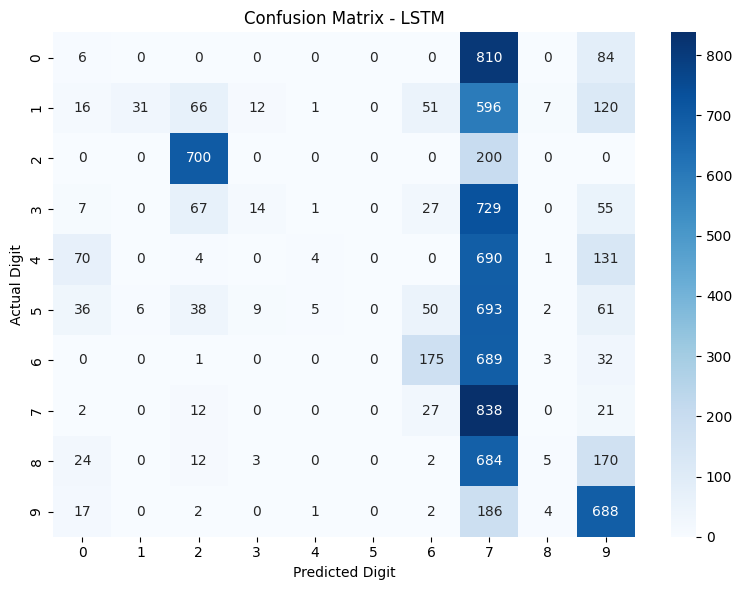

In [72]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

test_loss, test_accuracy = best_model.evaluate(
    X_test, y_test, verbose=0
)

print("Selected model:", best_model_name)
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test accuracy (%): {test_accuracy * 100:.2f}%")

y_pred = np.argmax(
    best_model.predict(X_test, verbose=0),
    axis=1
)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, digits=4))

plt.figure(figsize=(8, 6))
sns.heatmap(
    confusion_matrix(y_test, y_pred, labels=range(10)),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()